# United States Airlines Analysis — Capstone 2

**Objective:** identify factors behind *avoidable* flight delays and build a model that predicts whether a flight will be delayed.

Data: `Airlines.xlsx` (518k flights), `airports.xlsx` (OurAirports), `runways.xlsx`, plus two Wikipedia pages scraped for airline
founding years and US hub (passenger traffic) data. SQL tasks are in [`us_airlines.sql`](us_airlines.sql).

In [1]:
import io, os, re, time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 100
DATA = "../Dataset/Capstone_2/"
SEED = 42

## Week 1 — Data science
### 1a. Import & aggregate flights, airports and runways

In [2]:
t = time.time()
flights = pd.read_excel(DATA + "Airlines.xlsx")
airports = pd.read_excel(DATA + "airports.xlsx")
runways = pd.read_excel(DATA + "runways.xlsx")
print(f"Loaded in {time.time() - t:.0f}s:", flights.shape, airports.shape, runways.shape)
flights.head()

Loaded in 18s: (518556, 9) (73805, 18) (43977, 20)


,id,Airline,Flight,AirportFrom,AirportTo,DayOfWeek,Time,Length,Delay
0,1,CO,269,SFO,IAH,3,15,205,1
1,2,US,1558,PHX,CLT,3,15,222,1
2,3,AA,2400,LAX,DFW,3,20,165,1
3,4,AA,2466,SFO,DFW,3,20,195,1
4,5,AS,108,ANC,SEA,3,30,202,0


**Join keys:** `flights.AirportFrom / AirportTo` ↔ `airports.iata_code`, and `airports.ident` ↔ `runways.airport_ident`.
Runways are aggregated to one row per airport (count of open runways, longest/average length, average width, share of hard surfaces, lighting).

In [3]:
rw = runways[runways["closed"] == 0].copy()
rw["hard_surface"] = rw["surface"].fillna("").str.upper().str.contains("ASP|CON|PEM|BIT|TAR|ASPH")
rw_agg = rw.groupby("airport_ident").agg(
    num_runways=("id", "count"), max_runway_length_ft=("length_ft", "max"), avg_runway_length_ft=("length_ft", "mean"),
    avg_runway_width_ft=("width_ft", "mean"), hard_surface_share=("hard_surface", "mean"), lighted_share=("lighted", "mean"))

ap = airports.dropna(subset=["iata_code"]).copy()
type_rank = {"large_airport": 0, "medium_airport": 1, "small_airport": 2, "seaplane_base": 3, "heliport": 4, "closed": 5}
ap["_rank"] = ap["type"].map(type_rank).fillna(9)
ap = ap.sort_values("_rank").drop_duplicates("iata_code")          # one row per IATA code, prefer the larger airport
ap = ap.merge(rw_agg, left_on="ident", right_index=True, how="left")
ap_cols = ["iata_code", "type", "elevation_ft", "iso_region", "num_runways", "max_runway_length_ft",
           "avg_runway_length_ft", "avg_runway_width_ft", "hard_surface_share", "lighted_share"]
ap = ap[ap_cols]

df = flights.copy()
for side in ["From", "To"]:
    df = df.merge(ap.add_suffix(f"_{side}").rename(columns={f"iata_code_{side}": f"Airport{side}"}), on=f"Airport{side}", how="left")
print("Aggregated dataset:", df.shape)
print("Flights whose airports were matched:", df["type_From"].notna().mean().round(4), df["type_To"].notna().mean().round(4))
df.head(3).T

Aggregated dataset: (518556, 27)
Flights whose airports were matched: 0.9999 0.9999


,0,1,2
id,1,2,3
Airline,CO,US,AA
Flight,269,1558,2400
AirportFrom,SFO,PHX,LAX
AirportTo,IAH,CLT,DFW
DayOfWeek,3,3,3
Time,15,15,20
Length,205,222,165
Delay,1,1,1
type_From,large_airport,large_airport,large_airport


### 1b. Airline experience — scraped from Wikipedia
The airline list gives IATA codes and founding years for current carriers. Several carriers in this (older) dataset have since merged
(US Airways, Continental, ExpressJet, Comair, and Hawaiian — now part of Alaska Air Group), so their founding years are completed from their Wikipedia articles — values given in
the project brief are used where provided (US Airways Express 1967, Continental 1934, ExpressJet 1986).
Scraped tables are cached to CSV so the notebook also runs offline.

In [4]:
HEADERS = {"User-Agent": "Mozilla/5.0 (educational data-science project)"}
def scrape_tables(url, cache):
    if os.path.exists(cache):
        return None
    import requests
    html = requests.get(url, headers=HEADERS, timeout=30).text
    return pd.read_html(io.StringIO(html))

AIRLINE_CACHE = "scraped_airline_founding.csv"
tables = scrape_tables("https://en.wikipedia.org/wiki/List_of_airlines_of_the_United_States", AIRLINE_CACHE)
if tables is not None:
    wiki_air = pd.concat([t for t in tables if {"IATA", "Founded", "Airline"} <= set(t.columns)], ignore_index=True)
    wiki_air = wiki_air[["Airline", "IATA", "Founded"]].dropna(subset=["IATA"])
    wiki_air["Founded"] = wiki_air["Founded"].astype(str).str.extract(r"(\d{4})")[0].astype(float)
    wiki_air.drop_duplicates("IATA").to_csv(AIRLINE_CACHE, index=False)
wiki_air = pd.read_csv(AIRLINE_CACHE)
print(f"Scraped {len(wiki_air)} airlines")

codes = sorted(df["Airline"].unique())
airline_info = pd.DataFrame({"Airline": codes}).merge(wiki_air.rename(columns={"Airline": "airline_name", "IATA": "Airline"}), on="Airline", how="left")
# Carriers missing from the current list (defunct/merged) — founding years from their Wikipedia articles / the brief
manual = {"US": ("US Airways (Express)", 1967), "CO": ("Continental Airlines", 1934), "XE": ("ExpressJet", 1986),
          "EV": ("Atlantic Southeast (ExpressJet)", 1979), "OH": ("Comair", 1977), "9E": ("Pinnacle / Endeavor Air", 1985),
          "MQ": ("American Eagle (Envoy)", 1984), "YV": ("Mesa Airlines", 1980), "OO": ("SkyWest Airlines", 1972),
          "HA": ("Hawaiian Airlines", 1929)}
# XE and OH have been re-assigned to newer carriers (JSX, PSA). In this dataset they were ExpressJet and Comair, so always use the historical carrier.
FORCE = {"XE": ("ExpressJet Airlines", 1986), "OH": ("Comair", 1977)}
manual.update(FORCE)
for code, (name, year) in manual.items():
    m = airline_info["Airline"] == code
    if airline_info.loc[m, "Founded"].isna().all() or code in FORCE:
        airline_info.loc[m, ["airline_name", "Founded"]] = [name, year]
airline_info["source"] = np.where(airline_info["Airline"].isin([k for k in manual if k not in wiki_air["IATA"].values] + list(FORCE)), "manual", "scraped")
airline_info

Scraped 89 airlines


,Airline,airline_name,Founded,source
0,9E,Endeavor Air,1985.0,scraped
1,AA,American Airlines,1926.0,scraped
2,AS,Alaska Airlines,1932.0,scraped
3,B6,JetBlue,1998.0,scraped
4,CO,Continental Airlines,1934.0,manual
5,DL,Delta Air Lines,1924.0,scraped
6,EV,Atlantic Southeast (ExpressJet),1979.0,manual
7,F9,Frontier Airlines,1994.0,scraped
8,HA,Hawaiian Airlines,1929.0,manual
9,MQ,Envoy Air,1984.0,scraped


### 1c. Everything in one place

In [5]:
df = df.merge(airline_info[["Airline", "airline_name", "Founded"]], on="Airline", how="left")
df["airline_years_at_2010"] = 2010 - df["Founded"]       # approx. experience at the time of the flights (~2009-10 data)
df[["Airline", "airline_name", "Founded", "airline_years_at_2010"]].drop_duplicates().sort_values("Founded")

,Airline,airline_name,Founded,airline_years_at_2010
6,DL,Delta Air Lines,1924.0,86.0
87,UA,United Airlines,1926.0,84.0
2,AA,American Airlines,1926.0,84.0
23,HA,Hawaiian Airlines,1929.0,81.0
4,AS,Alaska Airlines,1932.0,78.0
0,CO,Continental Airlines,1934.0,76.0
456,WN,Southwest Airlines,1967.0,43.0
1,US,US Airways (Express),1967.0,43.0
29,OO,SkyWest Airlines,1972.0,38.0
38,OH,Comair,1977.0,33.0


### 1d. Passenger traffic & hub size — scraped from Wikipedia
Large hubs handle ≥ 1% of US enplanements, medium hubs 0.25-1%. All other airports are labelled `small/non-hub`.

In [6]:
HUB_CACHE = "scraped_us_hubs.csv"
tables = scrape_tables("https://en.wikipedia.org/wiki/List_of_the_busiest_airports_in_the_United_States", HUB_CACHE)
if tables is not None:
    rows = []
    for t in tables[:2]:
        size = "large" if any("large" in str(c).lower() for c in t.columns) else "medium"
        name_col = [c for c in t.columns if "Airports" in str(c)][0]
        year_cols = [c for c in t.columns if re.match(r"^20\d\d", str(c))]
        latest = year_cols[0]
        rows.append(pd.DataFrame({"iata": t["IATA Code"], "airport": t[name_col], "state": t["State"],
                                  "hub_size": size, "passengers_latest": pd.to_numeric(t[latest], errors="coerce"),
                                  "latest_year": re.match(r"^(20\d\d)", str(latest)).group(1)}))
    pd.concat(rows).to_csv(HUB_CACHE, index=False)
hubs = pd.read_csv(HUB_CACHE)
print(hubs["hub_size"].value_counts())
hubs.head()

hub_size
medium    35
large     30
Name: count, dtype: int64


,iata,airport,state,hub_size,passengers_latest,latest_year
0,ATL,Hartsfield–Jackson Atlanta International Airport,GA,large,51459786,2025
1,DFW,Dallas/Fort Worth International Airport,TX,large,41297009,2025
2,ORD,O'Hare International Airport,IL,large,40680735,2025
3,DEN,Denver International Airport,CO,large,39976695,2025
4,LAX,Los Angeles International Airport,CA,large,36497303,2025


In [7]:
hub_map = hubs.set_index("iata")["hub_size"]
pax_map = hubs.set_index("iata")["passengers_latest"]
for side in ["From", "To"]:
    df[f"hub_{side}"] = df[f"Airport{side}"].map(hub_map).fillna("small/non-hub")
    df[f"passengers_{side}"] = df[f"Airport{side}"].map(pax_map)
df[["hub_From", "hub_To"]].apply(pd.Series.value_counts)

,hub_From,hub_To
large,327330,327394
medium,100616,100629
small/non-hub,90610,90533


### 2. Missing values & treatment

In [8]:
miss = df.isna().mean().mul(100).round(2)
miss[miss > 0].sort_values(ascending=False)

passengers_From              17.47
passengers_To                17.46
avg_runway_width_ft_To        0.12
avg_runway_width_ft_From      0.12
iso_region_To                 0.01
lighted_share_To              0.01
hard_surface_share_To         0.01
avg_runway_length_ft_To       0.01
max_runway_length_ft_To       0.01
num_runways_To                0.01
type_From                     0.01
elevation_ft_From             0.01
type_To                       0.01
lighted_share_From            0.01
hard_surface_share_From       0.01
avg_runway_length_ft_From     0.01
max_runway_length_ft_From     0.01
num_runways_From              0.01
iso_region_From               0.01
elevation_ft_To               0.01
dtype: float64

In [9]:
unmatched = df.loc[df["type_From"].isna(), "AirportFrom"].unique().tolist() + df.loc[df["type_To"].isna(), "AirportTo"].unique().tolist()
print("Airports without a match in airports.xlsx:", sorted(set(unmatched)))

Airports without a match in airports.xlsx: ['CYS']


**Treatment & justification**
* `passengers_*` is missing for non-hub airports **by design** (they are not in the busiest-airports lists) → fill with **0**/flag via `hub_*`.
* Runway fields are missing only where an airport has no runway record → fill `num_runways` with the **median** of airports of the same type, and
  the remaining runway statistics with the overall median (very few rows; median is robust to the skewed length distribution).
* Airport attributes missing for the few codes not found in `airports.xlsx` → numeric fields with the median, `type` with `"unknown"`.
* No flight-level fields (`Airline`, `Time`, `Length`, `Delay`, ...) are missing, so no rows need to be dropped.

In [10]:
for side in ["From", "To"]:
    df[f"passengers_{side}"] = df[f"passengers_{side}"].fillna(0)
    df[f"type_{side}"] = df[f"type_{side}"].fillna("unknown")
    df[f"num_runways_{side}"] = df[f"num_runways_{side}"].fillna(df.groupby(f"type_{side}")[f"num_runways_{side}"].transform("median"))
    for c in ["elevation_ft", "num_runways", "max_runway_length_ft", "avg_runway_length_ft", "avg_runway_width_ft", "hard_surface_share", "lighted_share"]:
        df[f"{c}_{side}"] = df[f"{c}_{side}"].fillna(df[f"{c}_{side}"].median())
print("Remaining missing values (excluding text-only iso_region):", df.drop(columns=["iso_region_From", "iso_region_To"]).isna().sum().sum())

Remaining missing values (excluding text-only iso_region): 0


### 3. Visual insights
#### 3a. Southwest (~70% delayed) vs other airlines

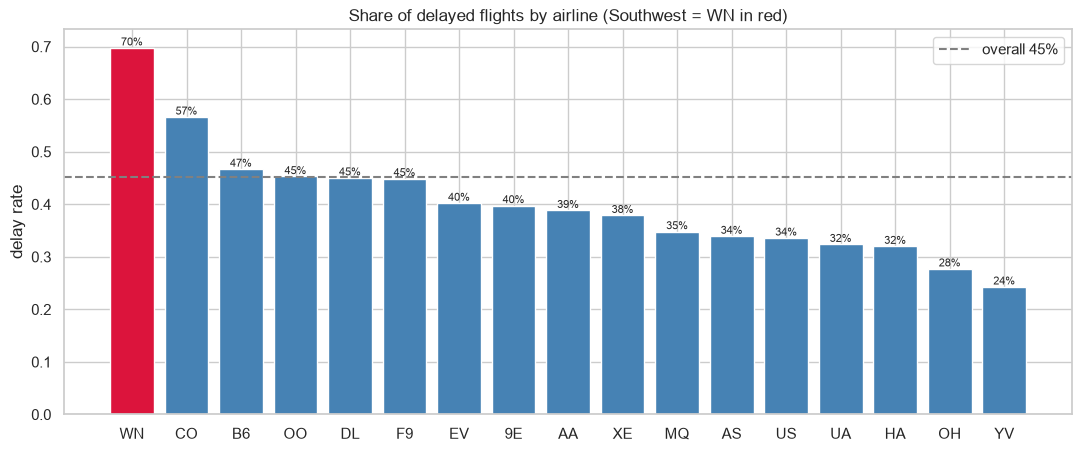

,Airline,airline_name,delay_rate,flights
14,WN,Southwest Airlines,0.698,94097
4,CO,Continental Airlines,0.566,21118
3,B6,JetBlue,0.467,18112
11,OO,SkyWest Airlines,0.453,50254
5,DL,Delta Air Lines,0.450,60940
7,F9,Frontier Airlines,0.449,6456
6,EV,Atlantic Southeast (ExpressJet),0.402,27983
0,9E,Endeavor Air,0.398,20686
1,AA,American Airlines,0.388,45656
15,XE,ExpressJet Airlines,0.379,31126


In [11]:
air = df.groupby(["Airline", "airline_name"])["Delay"].agg(delay_rate="mean", flights="size").reset_index().sort_values("delay_rate", ascending=False)
plt.figure(figsize=(13, 5))
colors = ["crimson" if a == "WN" else "steelblue" for a in air["Airline"]]
bars = plt.bar(air["Airline"], air["delay_rate"], color=colors)
plt.bar_label(bars, labels=[f"{v:.0%}" for v in air["delay_rate"]], fontsize=8); plt.ylabel("delay rate")
plt.axhline(df["Delay"].mean(), ls="--", color="grey", label=f"overall {df['Delay'].mean():.0%}")
plt.title("Share of delayed flights by airline (Southwest = WN in red)"); plt.legend(); plt.show()
air.round(3)

Southwest (WN) has by far the **highest delay rate (~70%)** and also the most flights. Continental (CO, ~57%) and JetBlue (B6, ~47%) follow.
The most punctual carriers are Mesa (YV, ~24%), Comair (OH, ~28%), Hawaiian (HA) and United (UA) (~32%).

#### 3b. Safest day of the week

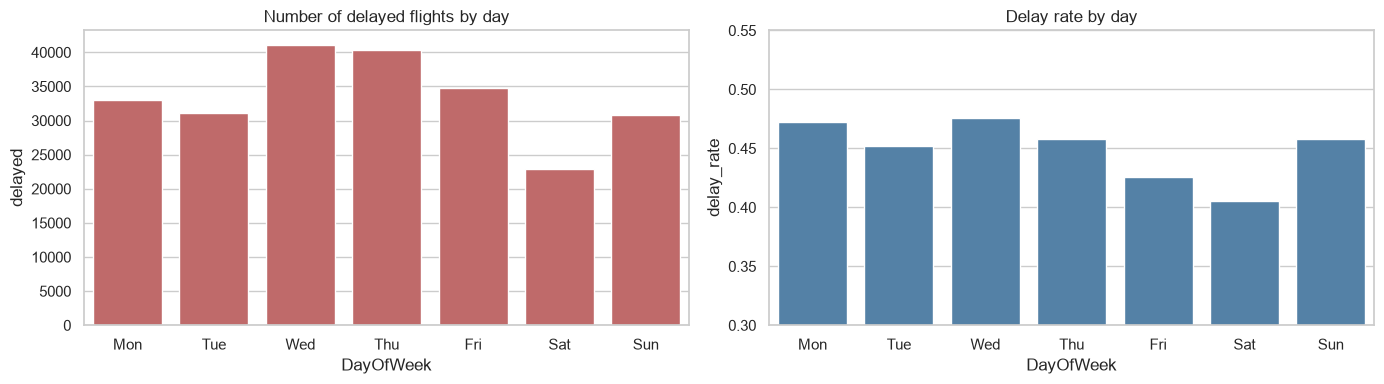

Safest day (lowest delay rate): Sat


,delay_rate,flights,delayed
DayOfWeek,,,
Mon,0.472,70008,33059
Tue,0.452,68721,31072
Wed,0.476,86478,41144
Thu,0.458,87988,40280
Fri,0.426,81797,34813
Sat,0.406,56354,22860
Sun,0.458,67210,30761


In [12]:
day_names = {1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat", 7: "Sun"}
dow = df.groupby("DayOfWeek")["Delay"].agg(delay_rate="mean", flights="size", delayed="sum")
dow.index = dow.index.map(day_names)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(x=dow.index, y=dow["delayed"], ax=axes[0], color="indianred"); axes[0].set_title("Number of delayed flights by day")
sns.barplot(x=dow.index, y=dow["delay_rate"], ax=axes[1], color="steelblue"); axes[1].set_title("Delay rate by day")
axes[1].set_ylim(0.3, 0.55); plt.tight_layout(); plt.show()
print("Safest day (lowest delay rate):", dow["delay_rate"].idxmin())
dow.round(3)

#### 3c. Best airlines for short, medium and long flights
Flight `Length` (minutes) is grouped into short (≤ 90), medium (91-180) and long (> 180).

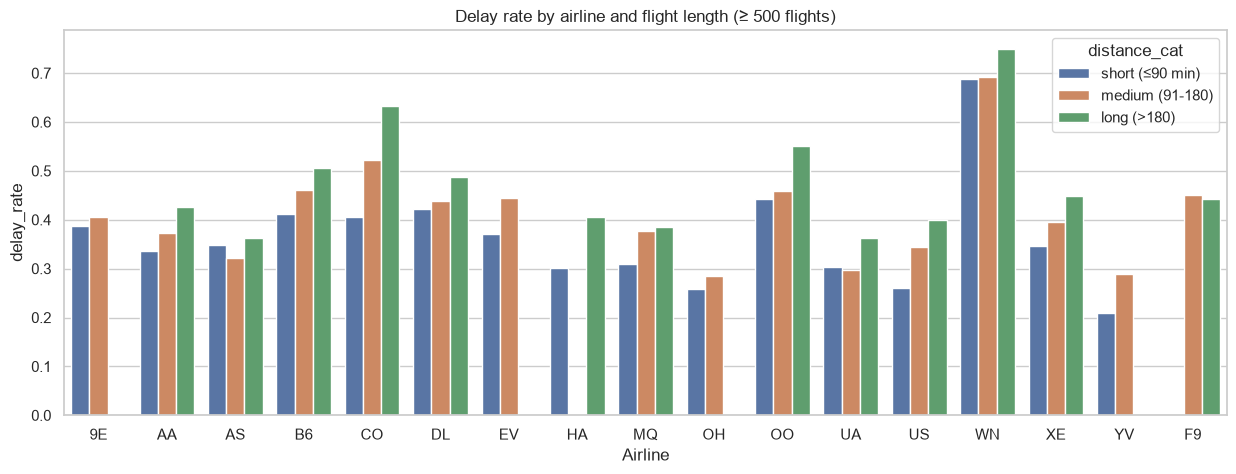

,distance_cat,Airline,delay_rate,flights,airline_name
0,short (≤90 min),YV,0.209,7825,Mesa Airlines
1,short (≤90 min),OH,0.258,3995,Comair
2,short (≤90 min),US,0.260,8719,US Airways (Express)
3,medium (91-180),OH,0.285,8201,Comair
4,medium (91-180),YV,0.288,5594,Mesa Airlines
5,medium (91-180),UA,0.297,14728,United Airlines
6,long (>180),AS,0.362,3601,Alaska Airlines
7,long (>180),UA,0.363,10930,United Airlines
8,long (>180),MQ,0.386,770,Envoy Air


In [13]:
df["distance_cat"] = pd.cut(df["Length"], bins=[-1, 90, 180, 10_000], labels=["short (≤90 min)", "medium (91-180)", "long (>180)"])
cat = df.groupby(["distance_cat", "Airline"], observed=True)["Delay"].agg(delay_rate="mean", flights="size").reset_index()
cat = cat[cat["flights"] >= 500]                          # ignore airlines with too few flights in a category
plt.figure(figsize=(15, 5))
sns.barplot(data=cat, x="Airline", y="delay_rate", hue="distance_cat"); plt.title("Delay rate by airline and flight length (≥ 500 flights)")
plt.show()
best = cat.sort_values("delay_rate").groupby("distance_cat", observed=True).head(3).sort_values(["distance_cat", "delay_rate"])
best.merge(airline_info[["Airline", "airline_name"]], on="Airline").round(3)

#### 3d. Departure times of long-duration flights

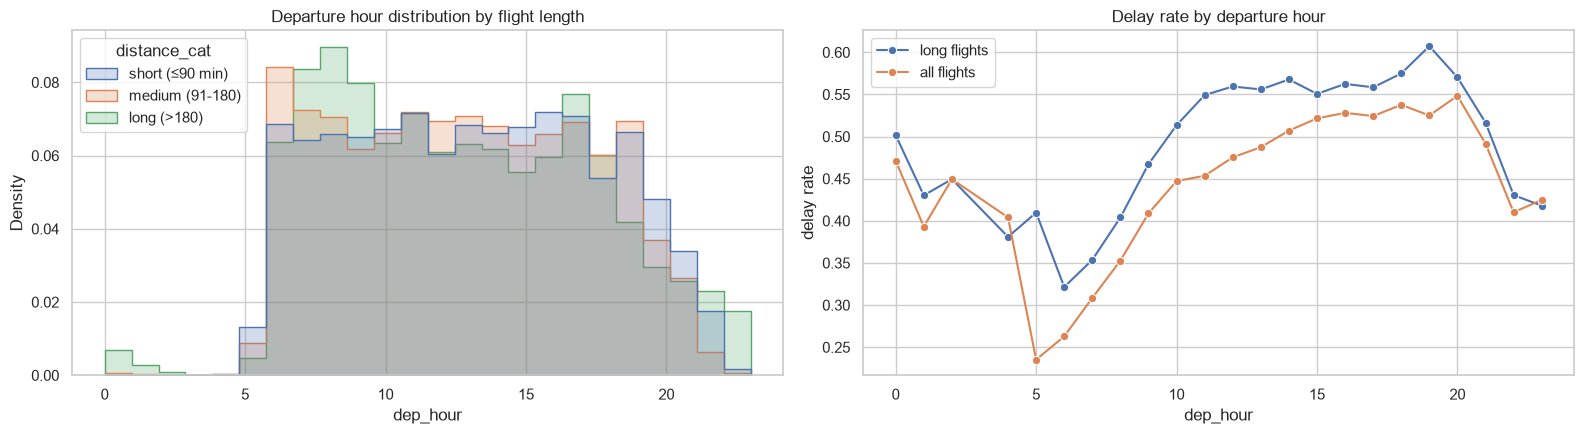

In [14]:
df["dep_hour"] = df["Time"] // 60
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
sns.histplot(data=df, x="dep_hour", hue="distance_cat", stat="density", common_norm=False, element="step", bins=24, ax=axes[0])
axes[0].set_title("Departure hour distribution by flight length")
long = df[df["distance_cat"] == "long (>180)"]
sns.lineplot(data=long.groupby("dep_hour")["Delay"].mean(), ax=axes[1], marker="o", label="long flights")
sns.lineplot(data=df.groupby("dep_hour")["Delay"].mean(), ax=axes[1], marker="o", label="all flights")
axes[1].set_title("Delay rate by departure hour"); axes[1].set_ylabel("delay rate")
plt.tight_layout(); plt.show()

Long flights depart mostly **early morning (6-9 h)** and again in the **late afternoon/evening** (transcontinental and red-eye flights after ~21 h).
Delay rates rise steadily through the day for all flights — delays propagate — so the **earliest departures are the most punctual**.

### 4. Delays at large vs medium hubs

delayed  flights  delay_rate
direction hub_size                                   
From      large           150538   327330       0.460
          medium           50823   100616       0.505
          small/non-hub    32628    90610       0.360
To        large           142457   327394       0.435
          medium           52486   100629       0.522
          small/non-hub    39046    90533       0.431

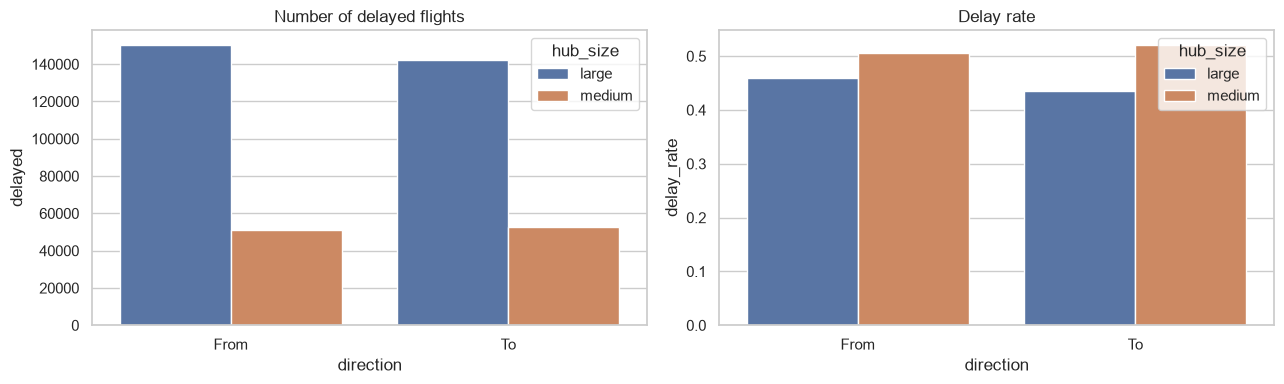

In [15]:
hub_tbl = pd.concat({side: df.groupby(f"hub_{side}")["Delay"].agg(delayed="sum", flights="size", delay_rate="mean")
                     for side in ["From", "To"]}, names=["direction", "hub_size"])
display(hub_tbl.round(3))
plot = hub_tbl.reset_index()
plot = plot[plot["hub_size"].isin(["large", "medium"])]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=plot, x="direction", y="delayed", hue="hub_size", ax=axes[0]); axes[0].set_title("Number of delayed flights")
sns.barplot(data=plot, x="direction", y="delay_rate", hue="hub_size", ax=axes[1]); axes[1].set_title("Delay rate")
plt.tight_layout(); plt.show()

**Large hubs** have by far the most delayed flights in absolute terms (≈150k departing, ≈142k arriving — 3× the medium hubs) because they
handle most traffic. In delay **rate**, however, **medium hubs are worse** (≈50-52% vs ≈44-46% for large hubs), and small/non-hub airports are
the most punctual. Medium hubs may have less spare capacity and fewer resources to absorb disruption.

### 5. Hypothesis tests (α = 0.05)
Delayed and on-time flights are compared with Welch t-tests (large samples) and Mann-Whitney U tests (distribution-free check).

In [16]:
def compare(col):
    a, b = df.loc[df.Delay == 1, col], df.loc[df.Delay == 0, col]
    t, p_t = stats.ttest_ind(a, b, equal_var=False); u, p_u = stats.mannwhitneyu(a, b)
    return {"variable": col, "mean_delayed": a.mean(), "mean_on_time": b.mean(), "t_p": p_t, "mw_p": p_u,
            "result": "REJECT H0 (related)" if p_u < 0.05 else "no evidence"}
tests = pd.DataFrame([compare(c) for c in ["elevation_ft_From", "elevation_ft_To", "num_runways_From", "num_runways_To", "Length"]])
tests["mean_diff_%"] = (tests["mean_delayed"] / tests["mean_on_time"] - 1) * 100
display(tests.round(4))

for col in ["elevation_ft_From", "num_runways_From", "Length"]:
    r, p = stats.pointbiserialr(df["Delay"], df[col])
    print(f"point-biserial r(Delay, {col}) = {r:.3f} (p = {p:.2g})")

,variable,mean_delayed,mean_on_time,t_p,mw_p,result,mean_diff_%
0,elevation_ft_From,911.1410,881.3263,0.0,0.0,REJECT H0 (related),3.3829
1,elevation_ft_To,913.4587,879.7092,0.0,0.0,REJECT H0 (related),3.8364
2,num_runways_From,4.0151,3.9132,0.0,0.0,REJECT H0 (related),2.6050
3,num_runways_To,3.8398,4.0583,0.0,0.0,REJECT H0 (related),-5.3833
4,Length,135.3962,129.6068,0.0,0.0,REJECT H0 (related),4.4669


point-biserial r(Delay, elevation_ft_From) = 0.011 (p = 7.8e-15)
point-biserial r(Delay, num_runways_From) = 0.031 (p = 2.5e-107)
point-biserial r(Delay, Length) = 0.041 (p = 3.2e-188)


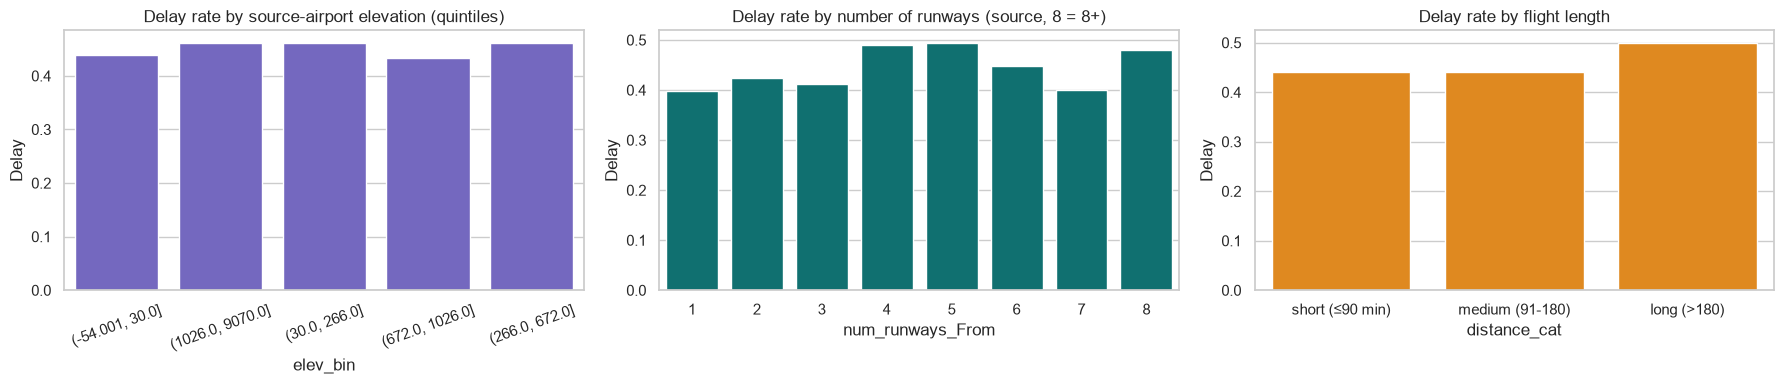

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
df["elev_bin"] = pd.qcut(df["elevation_ft_From"], 5, duplicates="drop")
sns.barplot(x=df["elev_bin"].astype(str), y=df["Delay"], ax=axes[0], errorbar=None, color="slateblue"); axes[0].set_title("Delay rate by source-airport elevation (quintiles)"); axes[0].tick_params(axis="x", rotation=20)
sns.barplot(x=df["num_runways_From"].clip(upper=8).astype(int), y=df["Delay"], ax=axes[1], errorbar=None, color="teal"); axes[1].set_title("Delay rate by number of runways (source, 8 = 8+)")
sns.barplot(x=df["distance_cat"], y=df["Delay"], ax=axes[2], errorbar=None, color="darkorange"); axes[2].set_title("Delay rate by flight length")
plt.tight_layout(); plt.show()

**Findings:** with 500k flights even tiny differences are statistically significant, so effect sizes matter:
* **Altitude** — statistically significant for both source and destination, but tiny: delayed flights' airports are only ~3-4% higher on
  average (r ≈ 0.01). Practically, altitude is not a meaningful delay factor.
* **Number of runways** — significant, with opposite directions: departing from airports with *more* runways is slightly more delay-prone
  (busy hubs), while arriving at airports with more runways is *less* delay-prone (more landing capacity).
* **Flight length** — significant: delayed flights are ~4% longer on average and the delay rate rises with length; still a weak effect (r ≈ 0.04).

### 6. Correlation between delay predictors

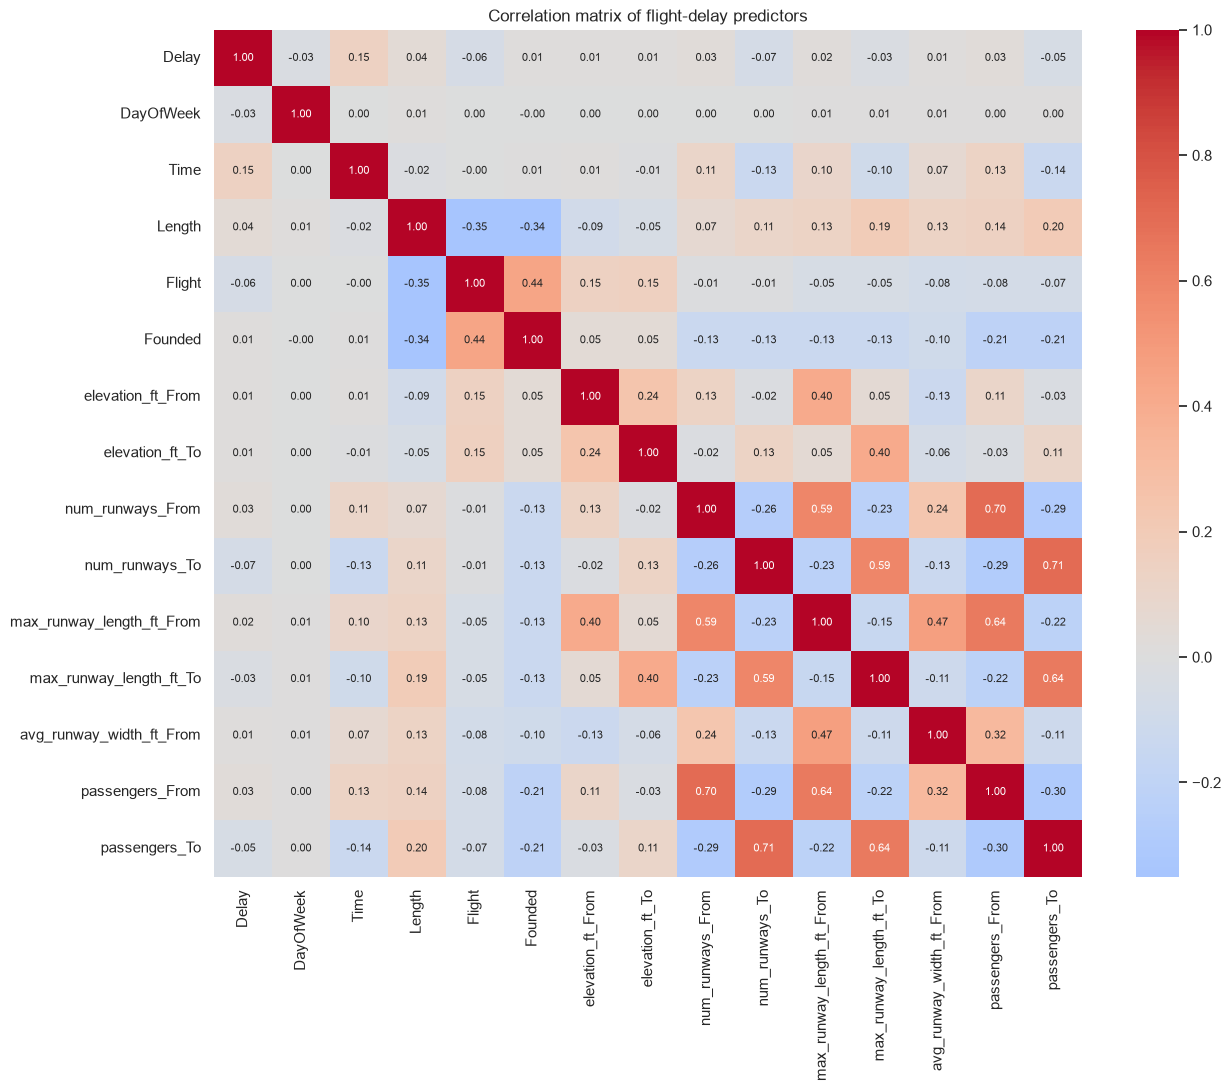

Time                         0.150
num_runways_To              -0.065
Flight                      -0.058
passengers_To               -0.050
Length                       0.041
num_runways_From             0.031
passengers_From              0.027
DayOfWeek                   -0.025
max_runway_length_ft_To     -0.025
max_runway_length_ft_From    0.019
avg_runway_width_ft_From     0.015
elevation_ft_To              0.012
elevation_ft_From            0.011
Founded                      0.010
Name: Delay, dtype: float64

In [18]:
num_feats = ["Delay", "DayOfWeek", "Time", "Length", "Flight", "Founded", "elevation_ft_From", "elevation_ft_To",
             "num_runways_From", "num_runways_To", "max_runway_length_ft_From", "max_runway_length_ft_To",
             "avg_runway_width_ft_From", "passengers_From", "passengers_To"]
plt.figure(figsize=(14, 11))
sns.heatmap(df[num_feats].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 8})
plt.title("Correlation matrix of flight-delay predictors"); plt.show()
df[num_feats].corr()["Delay"].drop("Delay").sort_values(key=abs, ascending=False).round(3)

* `Time` (departure time) is the strongest numeric correlate of delay — later departures are delayed more.
* Destination runways/passengers and `Flight` number are weakly negative (bigger destination airports and some carriers' flight-number
  ranges are associated with fewer delays); airline founding year has essentially no linear relationship with delay.
* Airport size variables (runways, runway length, passengers) are strongly inter-correlated with each other, so they carry overlapping information.
* All linear correlations are weak (|r| < 0.2): delay depends on interactions (airline × time × airport), which favours tree models.

## Week 1 — Machine learning
### 1. Encoding — OneHotEncoder & OrdinalEncoder
* **One-hot:** `Airline` (17 carriers), `DayOfWeek` (nominal).
* **Ordinal:** hub size (non-hub < medium < large) and airport type (small < medium < large) have a natural order.
* Numeric features are standardised **inside the pipeline**, so scaling is fitted on training folds only (no leakage).

In [19]:
df["dep_hour"] = df["Time"] // 60
hub_order = ["small/non-hub", "medium", "large"]
type_order = ["unknown", "closed", "heliport", "seaplane_base", "small_airport", "medium_airport", "large_airport"]
onehot_cols = ["Airline", "DayOfWeek"]
ordinal_cols = ["hub_From", "hub_To", "type_From", "type_To"]
numeric_cols = ["Time", "Length", "Flight", "Founded", "elevation_ft_From", "elevation_ft_To", "num_runways_From", "num_runways_To",
                "max_runway_length_ft_From", "max_runway_length_ft_To", "passengers_From", "passengers_To"]
X = df[onehot_cols + ordinal_cols + numeric_cols]
y = df["Delay"].values

def preprocessor():
    return ColumnTransformer([
        ("onehot", OneHotEncoder(handle_unknown="ignore"), onehot_cols),
        ("ordinal", OrdinalEncoder(categories=[hub_order, hub_order, type_order, type_order]), ordinal_cols),
        ("num", StandardScaler(), numeric_cols)])

### 2a-b. Train/test split & standardisation (inside pipelines)

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", X_train.shape, "Test:", X_test.shape, "| delay rate train/test:", y_train.mean().round(3), y_test.mean().round(3))

Train: (414844, 18) Test: (103712, 18) | delay rate train/test: 0.451 0.451


### 2c-e. Logistic regression (SGD) and decision tree, with overfitting control
The decision tree's depth and leaf size are tuned with 3-fold CV on a 100k sample to prevent overfitting (an unconstrained tree memorises the training data).

In [21]:
log_sgd = Pipeline([("prep", preprocessor()),
                    ("clf", SGDClassifier(loss="log_loss", penalty="l2", alpha=1e-4, max_iter=50, tol=1e-4, random_state=SEED))])
log_sgd.fit(X_train, y_train)

full_tree = Pipeline([("prep", preprocessor()), ("clf", DecisionTreeClassifier(random_state=SEED))]).fit(X_train, y_train)

sample = np.random.RandomState(SEED).choice(len(X_train), 100_000, replace=False)
tree_search = GridSearchCV(Pipeline([("prep", preprocessor()), ("clf", DecisionTreeClassifier(random_state=SEED))]),
                           {"clf__max_depth": [8, 12, 16, 20], "clf__min_samples_leaf": [20, 50, 100]},
                           cv=3, scoring="accuracy", n_jobs=-1).fit(X_train.iloc[sample], y_train[sample])
print("Best tree params:", tree_search.best_params_)
tree = Pipeline([("prep", preprocessor()), ("clf", DecisionTreeClassifier(random_state=SEED, **{k.split("__")[1]: v for k, v in tree_search.best_params_.items()}))]).fit(X_train, y_train)

def acc_row(name, m):
    return {"model": name, "train_acc": accuracy_score(y_train, m.predict(X_train)), "test_acc": accuracy_score(y_test, m.predict(X_test)),
            "test_auc": roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])}
acc = pd.DataFrame([acc_row("Logistic regression (SGD)", log_sgd), acc_row("Decision tree — unconstrained", full_tree),
                    acc_row("Decision tree — pruned/tuned", tree)]).set_index("model").round(4)
acc

Best tree params: {'clf__max_depth': 12, 'clf__min_samples_leaf': 100}


,train_acc,test_acc,test_auc
model,,,
Logistic regression (SGD),0.6347,0.6316,0.6764
Decision tree — unconstrained,0.8224,0.6083,0.6165
Decision tree — pruned/tuned,0.6589,0.6509,0.6958


The unconstrained tree reaches ~near-perfect training accuracy but much lower test accuracy — classic **overfitting**. Limiting depth and
leaf size closes the train/test gap and *improves* test accuracy.

### Final prediction by majority vote of 5 stratified-fold models
For each model type, 5 models are trained on the 5 stratified training folds; the test prediction is the **majority class** of the 5 votes.

In [22]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
def vote_ensemble(make_model, name):
    votes, fold_acc = [], []
    for k, (tr, va) in enumerate(skf.split(X_train, y_train)):
        m = make_model().fit(X_train.iloc[tr], y_train[tr])
        fold_acc.append(accuracy_score(y_train[va], m.predict(X_train.iloc[va])))
        votes.append(m.predict(X_test))
    votes = np.vstack(votes)
    final = (votes.sum(axis=0) >= 3).astype(int)
    return final, {"model": name, "mean_fold_val_acc": np.mean(fold_acc), "voted_test_acc": accuracy_score(y_test, final)}

best_tree_params = {k.split("__")[1]: v for k, v in tree_search.best_params_.items()}
make_log = lambda: Pipeline([("prep", preprocessor()), ("clf", SGDClassifier(loss="log_loss", alpha=1e-4, max_iter=50, tol=1e-4, random_state=SEED))])
make_tree = lambda: Pipeline([("prep", preprocessor()), ("clf", DecisionTreeClassifier(random_state=SEED, **best_tree_params))])
pred_log, r_log = vote_ensemble(make_log, "Logistic regression (SGD) — 5-fold vote")
pred_tree, r_tree = vote_ensemble(make_tree, "Decision tree — 5-fold vote")
vote_res = [r_log, r_tree]
pd.DataFrame(vote_res).set_index("model").round(4)

,mean_fold_val_acc,voted_test_acc
model,,
Logistic regression (SGD) — 5-fold vote,0.6335,0.6319
Decision tree — 5-fold vote,0.6501,0.6552


### 2g. Logistic regression vs decision tree

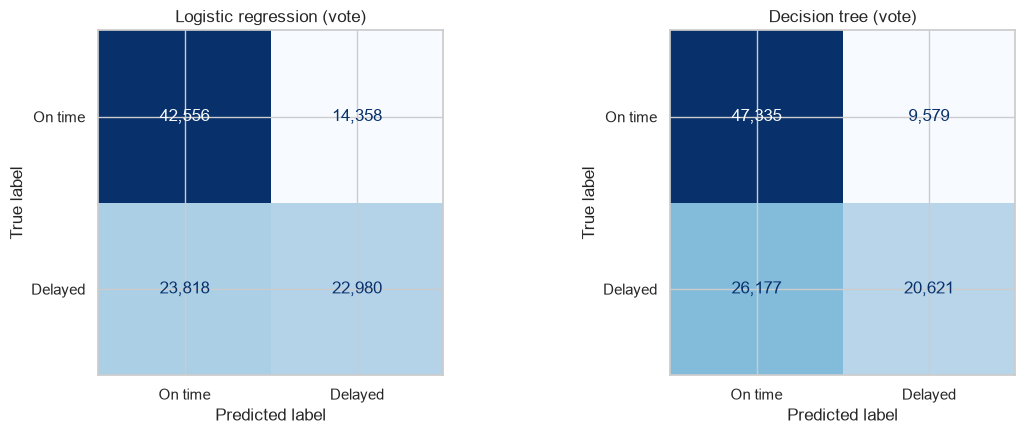

===== Logistic regression =====
               precision    recall  f1-score   support

     On time      0.641     0.748     0.690     56914
     Delayed      0.615     0.491     0.546     46798

    accuracy                          0.632    103712
   macro avg      0.628     0.619     0.618    103712
weighted avg      0.630     0.632     0.625    103712

===== Decision tree =====
               precision    recall  f1-score   support

     On time      0.644     0.832     0.726     56914
     Delayed      0.683     0.441     0.536     46798

    accuracy                          0.655    103712
   macro avg      0.663     0.636     0.631    103712
weighted avg      0.661     0.655     0.640    103712



In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (name, p) in zip(axes, [("Logistic regression (vote)", pred_log), ("Decision tree (vote)", pred_tree)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=["On time", "Delayed"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format=",")
    ax.set_title(name)
plt.tight_layout(); plt.show()
for name, p in [("Logistic regression", pred_log), ("Decision tree", pred_tree)]:
    print(f"===== {name} =====\n", classification_report(y_test, p, target_names=["On time", "Delayed"], digits=3))

The **decision tree clearly beats logistic regression**: delays depend on non-linear interactions (airline × departure time × airport) that a
linear model cannot capture.

### 3. Gradient Boosting — build, validate and compare
`HistGradientBoostingClassifier` (scikit-learn's histogram-based gradient boosting) is used because it handles 400k+ rows efficiently.

,mean_fold_val_acc,voted_test_acc,test_auc_single_model,train_acc_single_model
model,,,,
Logistic regression (SGD) — 5-fold vote,0.6335,0.6319,0.6764,0.6347
Decision tree — 5-fold vote,0.6501,0.6552,0.6958,0.6589
Gradient boosting — 5-fold vote,0.6672,0.6681,0.7225,0.6875


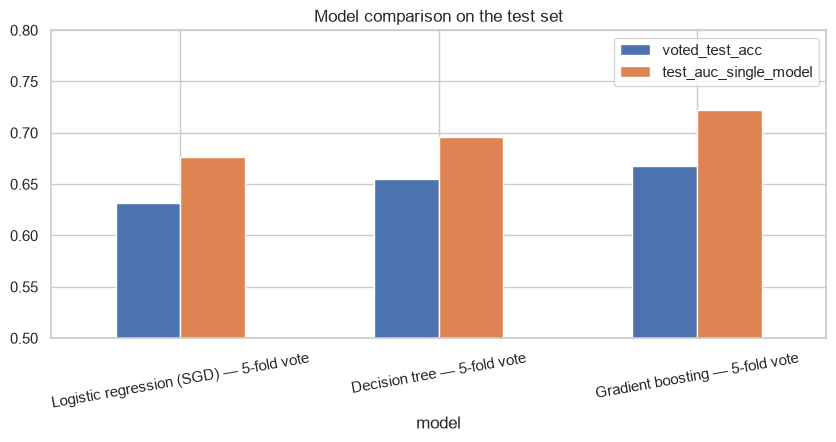

In [24]:
make_gb = lambda: Pipeline([("prep", preprocessor()),
                            ("clf", HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, max_leaf_nodes=63, random_state=SEED))])
pred_gb, r_gb = vote_ensemble(make_gb, "Gradient boosting — 5-fold vote")
gb_single = make_gb().fit(X_train, y_train)
vote_res.append(r_gb)

comparison = pd.DataFrame(vote_res).set_index("model")
comparison["test_auc_single_model"] = [roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]) for m in (log_sgd, tree, gb_single)]
comparison["train_acc_single_model"] = [accuracy_score(y_train, m.predict(X_train)) for m in (log_sgd, tree, gb_single)]
display(comparison.round(4))
ax = comparison[["voted_test_acc", "test_auc_single_model"]].plot.bar(figsize=(10, 4), rot=10, ylim=(0.5, 0.8))
ax.set_title("Model comparison on the test set"); plt.show()

## Conclusions
* **Avoidable delay factors:** carrier (Southwest's ~70% delay rate stands out), **departure time** (delays build up during the day),
  **hub congestion** (medium hubs have the highest delay rate, large hubs the most delayed flights) and, weakly, **longer flights**.
  **Saturday** is the safest day to travel (≈41% delayed vs ≈47% midweek); airport altitude has a negligible effect.
* **Recommendations:** fly early in the day; prefer the most punctual carriers per distance band (tables above); airlines should add schedule
  buffers for afternoon/evening departures at large hubs.
* **Models:** Gradient Boosting (voted test accuracy ≈ 0.67, AUC ≈ 0.72) > pruned Decision Tree (≈ 0.66, AUC ≈ 0.70) > Logistic Regression
  with SGD (≈ 0.63, AUC ≈ 0.68). Pruning (max_depth 12, min 100 samples per leaf) cut the tree's train/test gap from 0.82/0.61 to 0.66/0.65.
  Majority voting over 5 stratified-fold models gives stable predictions. Accuracy is moderate because many delay causes (weather, ATC,
  mechanical issues) are not in the data.

In [25]:
# Export tidy tables for the SQL tasks (us_airlines.sql)
os.makedirs("sql_data", exist_ok=True)
flights.to_csv("sql_data/flights.csv", index=False)
ap_out = ap[ap["iata_code"].isin(set(flights.AirportFrom) | set(flights.AirportTo))][["iata_code", "type", "elevation_ft", "num_runways"]]
ap_out.to_csv("sql_data/airports.csv", index=False)
airline_info[["Airline", "airline_name", "Founded"]].to_csv("sql_data/airlines.csv", index=False)
print("Exported:", {f: os.path.getsize("sql_data/" + f) // 1024 for f in os.listdir("sql_data")}, "KB")

Exported: {'airlines.csv': 0, 'airports.csv': 8, 'flights.csv': 17388} KB
